# Homework 6

**Выполнил:** Сидоров, РИС-24-1-1  
**Задача:** определить, является ли фильм хорошим, по тексту его описания, пяти главным актёрам и режиссёру.

Класс `1` присваивается фильму с `vote_average > 6`, класс `0` — фильму с `vote_average ≤ 6`. Оценка используется только для формирования целевой переменной и не передаётся моделям как входной признак.

Используются два файла набора TMDB 5000: `tmdb_5000_movies.csv` и `tmdb_5000_credits.csv`. Таблицы объединяются по идентификаторам `id` и `movie_id`.

Источник: [TMDB 5000 Movie Dataset](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata). Файл credits загружен из [публичной копии набора](https://github.com/missvicki/TMDb-movie-data). Это собственная постановка задачи на текстах описаний, соответствующая пункту 2.1.

Для повторного запуска установите зависимости командой `%pip install -r requirements.txt` в отдельной ячейке и выберите Python-ядро с этими библиотеками. При первом запуске необходимые языковые ресурсы NLTK загружаются автоматически.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

%matplotlib inline

import json
import re
import zlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk import pos_tag
from nltk.stem import PorterStemmer, WordNetLemmatizer
from gensim.models import Word2Vec

from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

for resource, path in [
    ("wordnet", "corpora/wordnet.zip"),
    ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng"),
]:
    try:
        nltk.data.find(path)
    except LookupError:
        if not nltk.download(resource, quiet=True):
            raise RuntimeError(f"Не удалось загрузить ресурс NLTK: {resource}")

## 1.1. Загрузка данных и формирование класса

Поле `cast` содержит список актёров. Берутся пять первых исполнителей по полю `order`, то есть актёры главных ролей. Из `crew` выбирается человек с должностью `Director`. Имена преобразуются в единые токены, например `actor_tom_hanks`, чтобы модель воспринимала имя целиком.

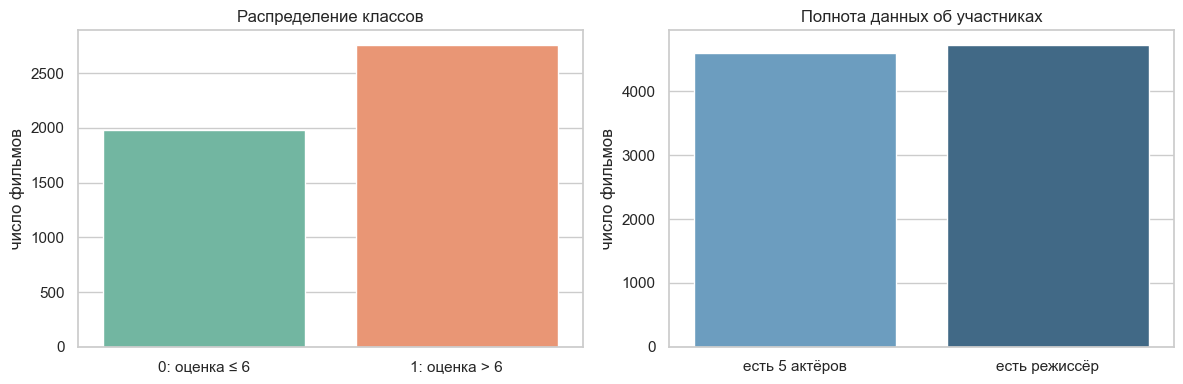

Фильмов после объединения и удаления пустых описаний: 4737
Распределение классов: {0: 1983, 1: 2754}
Полнота метаданных: {'есть 5 актёров': 4599, 'есть режиссёр': 4721}


,title,overview,cast_tokens,director_token,vote_average,good_movie
0,Avatar,"In the 22nd century, a paraplegic Marine is di...","[actor_sam_worthington, actor_zoe_saldana, act...",director_james_cameron,7.2,1
1,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...","[actor_johnny_depp, actor_orlando_bloom, actor...",director_gore_verbinski,6.9,1
2,Spectre,A cryptic message from Bond’s past sends him o...,"[actor_daniel_craig, actor_christoph_waltz, ac...",director_sam_mendes,6.3,1


In [2]:
movies = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv")

data = movies.merge(
    credits,
    left_on="id",
    right_on="movie_id",
    how="inner",
    suffixes=("", "_credits"),
    validate="one_to_one",
)
data = data.loc[
    data["overview"].fillna("").str.strip().ne("")
    & data["vote_average"].gt(0)
    & data["vote_count"].gt(0)
].copy().reset_index(drop=True)
data["good_movie"] = (data["vote_average"] > 6).astype(int)

def read_json_list(value):
    try:
        result = json.loads(value)
        return result if isinstance(result, list) else []
    except (TypeError, json.JSONDecodeError):
        return []

def person_token(prefix, name):
    normalized = re.sub(r"[^a-z]+", "_", str(name).lower()).strip("_")
    return f"{prefix}_{normalized}" if normalized else ""

def extract_cast(value, limit=5):
    people = sorted(read_json_list(value), key=lambda item: item.get("order", 10**6))[:limit]
    return [person_token("actor", item.get("name", "")) for item in people if item.get("name")]

def extract_director(value):
    directors = [item for item in read_json_list(value) if item.get("job") == "Director"]
    return person_token("director", directors[0].get("name", "")) if directors else ""

data["cast_tokens"] = data["cast"].apply(extract_cast)
data["director_token"] = data["crew"].apply(extract_director)
data["metadata_tokens"] = data.apply(
    lambda row: row["cast_tokens"] + ([row["director_token"]] if row["director_token"] else []),
    axis=1,
)

class_counts = data["good_movie"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=["0: оценка ≤ 6", "1: оценка > 6"], y=class_counts.values, ax=axes[0], palette="Set2")
axes[0].set_title("Распределение классов")
axes[0].set_ylabel("число фильмов")
axes[0].set_xlabel("")

metadata_counts = pd.Series({
    "есть 5 актёров": data["cast_tokens"].str.len().eq(5).sum(),
    "есть режиссёр": data["director_token"].ne("").sum(),
})
sns.barplot(x=metadata_counts.index, y=metadata_counts.values, ax=axes[1], palette="Blues_d")
axes[1].set_title("Полнота данных об участниках")
axes[1].set_ylabel("число фильмов")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

print("Фильмов после объединения и удаления пустых описаний:", len(data))
print("Распределение классов:", class_counts.to_dict())
print("Полнота метаданных:", metadata_counts.to_dict())
display(data[["title", "overview", "cast_tokens", "director_token", "vote_average", "good_movie"]].head(3))

**Интерпретация графиков.** После объединения остались 4737 фильмов с непустым описанием и пользовательской оценкой. Класс `1` содержит 2754 фильма (58,1 %), класс `0` — 1983 (41,9 %): хорошие фильмы встречаются чаще, но меньший класс тоже хорошо представлен. Поэтому Accuracy следует рассматривать совместно с F1, Precision, Recall и ROC-AUC.

На правом графике видно, что метаданные почти полны: у 4599 фильмов известны минимум пять актёров (97,1 %), а у 4721 указан режиссёр (99,7 %). Для остальных записей берутся только известные участники; имена не выдумываются.

## 1.1. Базовая предобработка текста

Для `overview` выполняются приведение к нижнему регистру, удаление пунктуации и специальных символов, токенизация, удаление английских стоп-слов и стемминг Портера. Стемминг сокращает слова до общей основы: `playing` и `played` превращаются в `play`. После обработки к словам описания добавляются пять актёров и режиссёр. Имена сохраняются целыми токенами без стемминга.

Если у фильма отсутствует часть актёрского состава или режиссёр, используются только известные участники. Фильмы без описания и без пользовательской оценки исключаются: ноль при отсутствии голосов не означает отрицательную оценку.

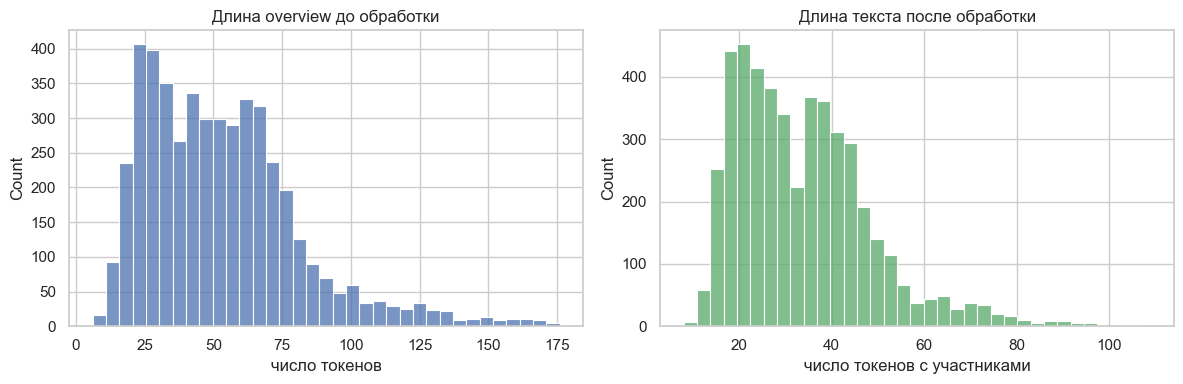

Уникальных слов до обработки: 20734
Примеры стемминга: {'playing': 'play', 'played': 'play', 'stories': 'stori', 'movies': 'movi'}
Средняя длина до обработки: 53.2
Средняя длина после обработки: 33.8
Пример подготовленного текста:
 centuri parapleg marin dispatch moon pandora uniqu mission torn follow order protect alien civil actor_sam_worthington actor_zoe_saldana actor_sigourney_weaver actor_stephen_lang actor_michelle_rodriguez director_james_cameron


In [3]:
TOKEN_PATTERN = re.compile(r"\b[a-z]+\b")
STOP_WORDS = set(ENGLISH_STOP_WORDS)
stemmer = PorterStemmer()

def tokenize_overview(text):
    return TOKEN_PATTERN.findall(str(text).lower())

raw_tokens = data["overview"].apply(tokenize_overview)
word_frequency = Counter(token for tokens in raw_tokens for token in tokens)

def clean_tokens(tokens):
    return [token for token in tokens if token not in STOP_WORDS and len(token) > 1]

data["raw_tokens"] = raw_tokens
data["overview_tokens"] = raw_tokens.apply(clean_tokens)
data["stem_tokens"] = data["overview_tokens"].apply(lambda tokens: [stemmer.stem(t) for t in tokens])
data["tokens"] = data.apply(lambda row: row["stem_tokens"] + row["metadata_tokens"], axis=1)
data["text"] = data["tokens"].str.join(" ")

raw_lengths = raw_tokens.str.len()
clean_lengths = data["tokens"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw_lengths, bins=35, ax=axes[0], color="#4C72B0")
axes[0].set_title("Длина overview до обработки")
axes[0].set_xlabel("число токенов")
sns.histplot(clean_lengths, bins=35, ax=axes[1], color="#55A868")
axes[1].set_title("Длина текста после обработки")
axes[1].set_xlabel("число токенов с участниками")
plt.tight_layout()
plt.show()

print("Уникальных слов до обработки:", len(word_frequency))
print("Примеры стемминга:", {word: stemmer.stem(word) for word in ["playing", "played", "stories", "movies"]})
print("Средняя длина до обработки:", round(raw_lengths.mean(), 1))
print("Средняя длина после обработки:", round(clean_lengths.mean(), 1))
print("Пример подготовленного текста:\n", data.iloc[0]["text"][:700])

**Интерпретация гистограмм.** Оба распределения имеют длинный правый хвост: большинство описаний короткие или средней длины, а очень длинные встречаются редко. После удаления стоп-слов средняя длина уменьшается с 53.2 до 33.8 токена даже с учётом добавленных имён участников. Это ожидаемо: служебные слова удаляются, а к описанию добавляются максимум шесть токенов метаданных. Стемминг изменяет форму слов, но сам по себе не сокращает их количество.

Сопоставляются исходный `overview` и итоговый текст с участниками, поэтому разница длин отражает сразу удаление стоп-слов и добавление метаданных. Конкретные примеры стемминга показаны под графиками: например, `playing` и `played` получают общую основу `play`.

## Разбиение данных и общая функция оценки

Данные делятся на обучающую и тестовую части в отношении 80/20 со стратификацией. Тестовая выборка не балансируется. В обучающей выборке меньший класс увеличивается простым upsampling до размера большего класса.

Используются три изученные ранее модели: kNN, линейный SVM и Logistic Regression. Для каждого метода рассчитываются Accuracy, F1, Precision, Recall и ROC-AUC. Для ROC используются вероятности kNN и Logistic Regression, а для SVM — значения `decision_function`.

In [4]:
indices = np.arange(len(data))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data["good_movie"],
)
y = data["good_movie"].to_numpy()
y_train, y_test = y[train_idx], y[test_idx]

def upsample_train(X, y_values):
    rng = np.random.default_rng(RANDOM_STATE)
    classes, counts = np.unique(y_values, return_counts=True)
    target_count = counts.max()
    selected = []
    for cls, count in zip(classes, counts):
        cls_idx = np.flatnonzero(y_values == cls)
        selected.extend(cls_idx)
        if count < target_count:
            selected.extend(rng.choice(cls_idx, size=target_count - count, replace=True))
    selected = np.asarray(selected)
    rng.shuffle(selected)
    return X[selected], y_values[selected]

def model_set(dense=False):
    svm = LinearSVC(C=1.0, max_iter=10_000, random_state=RANDOM_STATE)
    logreg = LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE)
    if dense:
        svm = make_pipeline(StandardScaler(), svm)
        logreg = make_pipeline(StandardScaler(), logreg)
    return {
        "kNN": KNeighborsClassifier(n_neighbors=15, weights="distance", metric="cosine", algorithm="brute"),
        "SVM": svm,
        "Logistic Regression": logreg,
    }

def evaluate_models(X_train, X_test, representation, dense=False):
    X_balanced, y_balanced = upsample_train(X_train, y_train)
    rows, curves = [], {}
    for name, model in model_set(dense=dense).items():
        fitted = clone(model).fit(X_balanced, y_balanced)
        prediction = fitted.predict(X_test)
        if hasattr(fitted, "predict_proba"):
            score = fitted.predict_proba(X_test)[:, 1]
        else:
            score = fitted.decision_function(X_test)
        rows.append({
            "представление": representation,
            "модель": name,
            "Accuracy": accuracy_score(y_test, prediction),
            "F1": f1_score(y_test, prediction),
            "Precision": precision_score(y_test, prediction, zero_division=0),
            "Recall": recall_score(y_test, prediction, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, score),
        })
        curves[name] = roc_curve(y_test, score)

    result = pd.DataFrame(rows)
    display(result.set_index("модель").drop(columns="представление").round(3))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    metric_long = result.melt(
        id_vars=["представление", "модель"],
        value_vars=["Accuracy", "F1", "Precision", "Recall"],
        var_name="метрика",
        value_name="значение",
    )
    sns.barplot(data=metric_long, x="метрика", y="значение", hue="модель", ax=axes[0])
    axes[0].set_ylim(0, 1)
    axes[0].set_title(f"Метрики: {representation}")
    axes[0].set_xlabel("")

    for name, (fpr, tpr, _) in curves.items():
        auc = result.loc[result["модель"] == name, "ROC-AUC"].iloc[0]
        axes[1].plot(fpr, tpr, label=f"{name}: {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"ROC-кривые: {representation}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    return result

print("Обучающая выборка:", len(train_idx), "Тестовая выборка:", len(test_idx))
print("Классы в train до upsampling:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Классы в train после upsampling:", {0: int(max(np.bincount(y_train))), 1: int(max(np.bincount(y_train)))})

# Простая контрольная модель: всем фильмам присваивается самый частый класс train.
majority_class = int(np.bincount(y_train).argmax())
baseline_pred = np.full_like(y_test, majority_class)
print(
    "Контрольная модель постоянного класса:",
    f"Accuracy={accuracy_score(y_test, baseline_pred):.3f},",
    f"F1={f1_score(y_test, baseline_pred):.3f}, ROC-AUC=0.500",
)

Обучающая выборка: 3789 Тестовая выборка: 948
Классы в train до upsampling: {0: 1586, 1: 2203}
Классы в train после upsampling: {0: 2203, 1: 2203}
Контрольная модель постоянного класса: Accuracy=0.581, F1=0.735, ROC-AUC=0.500


## 1.2–1.4. Bag of Words после стемминга и три модели

Bag of Words представляет каждый фильм вектором частот слов и биграмм после стемминга. Словарь строится только по обучающей выборке. Признаки, встретившиеся менее чем в двух обучающих документах, удаляются; размер словаря ограничивается 20 000 признаков. Косинусная метрика и веса соседей по расстоянию используются для kNN, регуляризация — для SVM и Logistic Regression. Эти настройки и upsampling train служат приёмами повышения качества; их отдельный эффект здесь не измеряется.

Размер матрицы train: (3789, 16781)
Пример признаков: ['aaron' 'abandon' 'abandon long' 'abandon town' 'abba' 'abbi' 'abdic'
 'abduct' 'abel' 'abigail' 'abil' 'abil commun' 'abl' 'aboard'
 'aboard ship' 'abolish' 'abolitionist' 'abort' 'abraham' 'abroad']


,Accuracy,F1,Precision,Recall,ROC-AUC
модель,,,,,
kNN,0.561,0.601,0.637,0.568,0.591
SVM,0.593,0.661,0.641,0.682,0.609
Logistic Regression,0.605,0.671,0.651,0.691,0.612


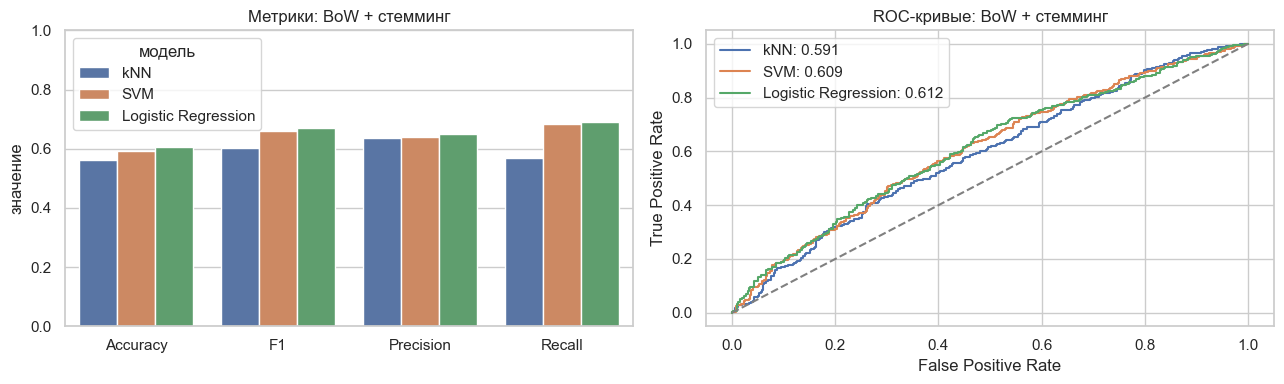

In [5]:
bow = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000)
X_train_bow = bow.fit_transform(data.iloc[train_idx]["text"])
X_test_bow = bow.transform(data.iloc[test_idx]["text"])

print("Размер матрицы train:", X_train_bow.shape)
print("Пример признаков:", bow.get_feature_names_out()[:20])
results_bow = evaluate_models(X_train_bow, X_test_bow, "BoW + стемминг")

**Интерпретация Bag of Words.** На столбчатой диаграмме Logistic Regression даёт лучший F1 среди трёх моделей (0.671); её Accuracy составляет 0.605, Precision — 0.651, Recall — 0.691. Это означает, что модель находит примерно 69.1 % фильмов класса «хороший», а среди предсказанных хороших фильмов примерно 65.1 % действительно имеют оценку выше 6. SVM близок по качеству, а kNN заметно отстаёт по F1 (0.601).

На ROC-графике все кривые расположены лишь немного выше диагонали. Максимальная ROC-AUC равна 0.612, поэтому разделение классов слабое: описание сюжета и имена участников содержат некоторый сигнал о рейтинге, но не позволяют надёжно определить оценку фильма.

## 1.5. Лемматизация и повторная классификация

Лемматизация приводит разные формы слова к общей словарной форме: например, `films` превращается в `film`, а `stories` — в `story`. Она выполняется по исходным токенам, **вместо стемминга**, с учётом части речи. POS-теги определяются до удаления стоп-слов, пока сохранён контекст предложения. Служебные токены актёров и режиссёров не изменяются. Затем снова используется Bag of Words и те же модели.

Размер словаря BoW со стеммингом: 16781
Размер словаря BoW с лемматизацией: 17267


,Accuracy,F1,Precision,Recall,ROC-AUC
модель,,,,,
kNN,0.557,0.589,0.639,0.546,0.588
SVM,0.599,0.663,0.648,0.679,0.600
Logistic Regression,0.608,0.671,0.654,0.690,0.607


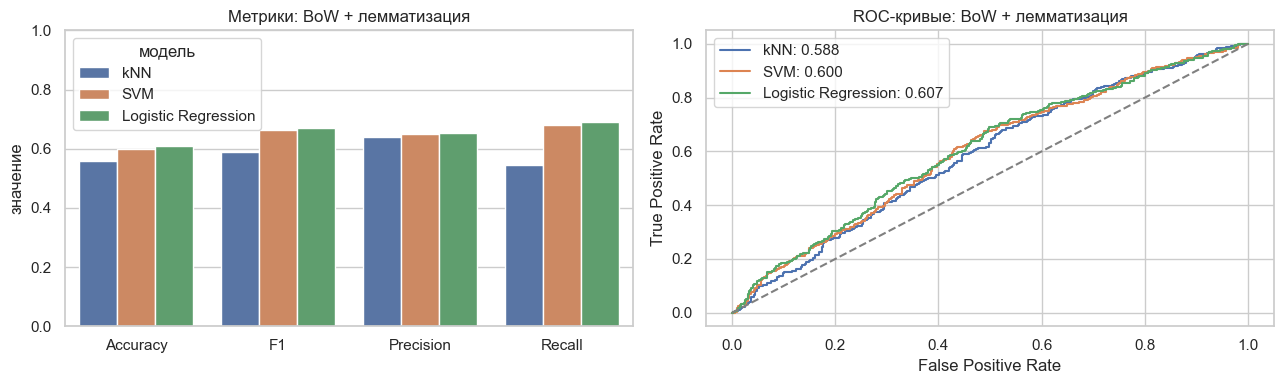

In [6]:
lemmatizer = WordNetLemmatizer()

def lemmatize_tagged(tagged):
    result = []
    wn_pos = {"J": "a", "V": "v", "N": "n", "R": "r"}
    for token, tag in tagged:
        if token not in STOP_WORDS and len(token) > 1:
            result.append(lemmatizer.lemmatize(token, pos=wn_pos.get(tag[0], "n")))
    return result

data["tagged_overview"] = data["raw_tokens"].apply(pos_tag)
data["lemma_overview"] = data["tagged_overview"].apply(lemmatize_tagged)
data["lemma_tokens"] = data.apply(lambda row: row["lemma_overview"] + row["metadata_tokens"], axis=1)
data["lemma_text"] = data["lemma_tokens"].str.join(" ")

bow_lemma = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000)
X_train_bow_lemma = bow_lemma.fit_transform(data.iloc[train_idx]["lemma_text"])
X_test_bow_lemma = bow_lemma.transform(data.iloc[test_idx]["lemma_text"])

print("Размер словаря BoW со стеммингом:", len(bow.vocabulary_))
print("Размер словаря BoW с лемматизацией:", len(bow_lemma.vocabulary_))
results_lemma = evaluate_models(X_train_bow_lemma, X_test_bow_lemma, "BoW + лемматизация")

**Интерпретация лемматизации.** Замена стемминга лемматизацией не привела к устойчивому улучшению всех моделей. У Logistic Regression F1 изменился с 0.671 до 0.671, Accuracy — с 0.605 до 0.608, а ROC-AUC — с 0.612 до 0.607. На диаграмме изменения малы; результаты остальных моделей показаны в таблице и столбцах рядом.

На ROC-графике кривые по-прежнему близки к диагонали. Лемматизация сохраняет словарные формы точнее, чем стемминг, но это не гарантирует лучшего прогноза рейтинга. Размеры словарей приведены над таблицей: сравниваются два альтернативных способа нормализации, поэтому после лемматизации словарь может оказаться больше, чем после более агрессивного стемминга.

## Дополнительная часть +1: TF-IDF

TF-IDF уменьшает вес слов, встречающихся почти во всех документах, и увеличивает влияние слов, характерных для отдельных описаний. Используются лемматизированные тексты, униграммы и биграммы.

Размер TF-IDF матрицы train: (3789, 17267)


,Accuracy,F1,Precision,Recall,ROC-AUC
модель,,,,,
kNN,0.560,0.594,0.641,0.554,0.612
SVM,0.610,0.674,0.655,0.695,0.626
Logistic Regression,0.621,0.681,0.667,0.695,0.640


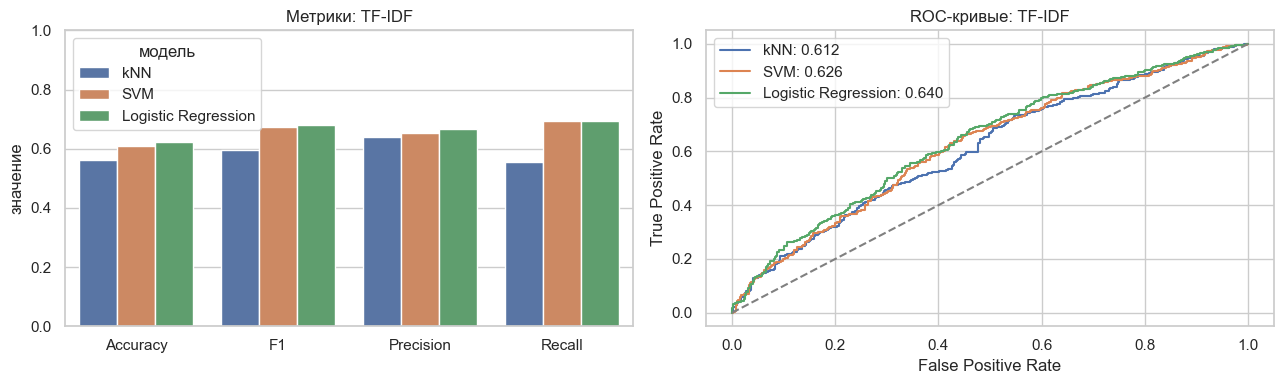

In [7]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=20_000,
    sublinear_tf=True,
)
X_train_tfidf = tfidf.fit_transform(data.iloc[train_idx]["lemma_text"])
X_test_tfidf = tfidf.transform(data.iloc[test_idx]["lemma_text"])

print("Размер TF-IDF матрицы train:", X_train_tfidf.shape)
results_tfidf = evaluate_models(X_train_tfidf, X_test_tfidf, "TF-IDF")

**Интерпретация TF-IDF.** У Logistic Regression относительно BoW с лемматизацией Accuracy меняется с 0.608 до 0.621, F1 — с 0.671 до 0.681, Precision — с 0.654 до 0.667, Recall — с 0.690 до 0.695. SVM также использует новую систему весов достаточно успешно; для kNN эффект следует оценивать отдельно по его строке таблицы.

На ROC-графике лучшая площадь под кривой составляет 0.640. Взвешивание признаков уменьшает влияние общеупотребительных слов и позволяет линейным моделям лучше использовать характерные слова и имена. Однако ROC-кривые всё ещё далеки от верхнего левого угла, поэтому качество остаётся умеренным.

## Дополнительная часть +2: Word2Vec

Word2Vec обучается только на текстах обучающей выборки. Метод размещает слова в плотном векторном пространстве: слова, употребляющиеся в похожем контексте, получают близкие векторы. Вектор фильма рассчитывается как среднее векторов его слов.

Размер словаря Word2Vec: 11694
Размер плотной матрицы train: (3789, 100)


,Accuracy,F1,Precision,Recall,ROC-AUC
модель,,,,,
kNN,0.578,0.639,0.636,0.642,0.595
SVM,0.566,0.604,0.644,0.568,0.604
Logistic Regression,0.566,0.604,0.644,0.568,0.604


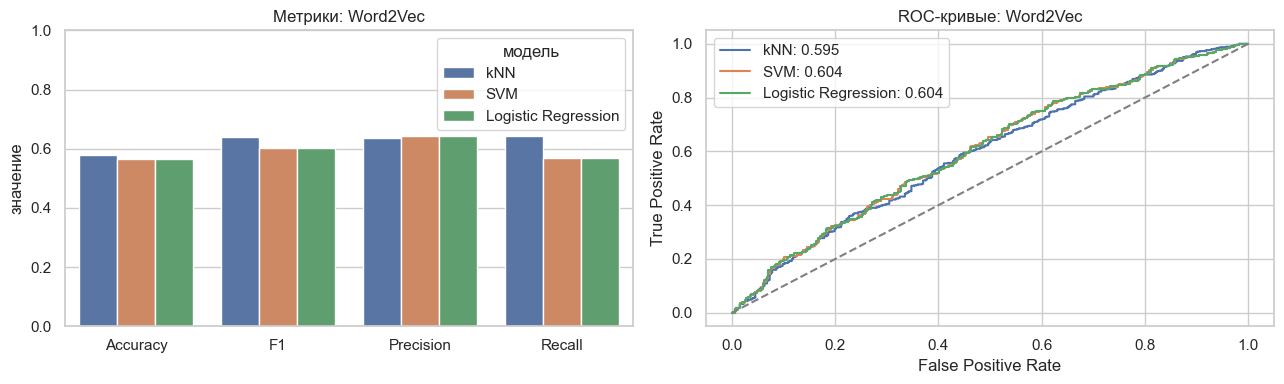

In [8]:
train_sentences = data.iloc[train_idx]["lemma_tokens"].tolist()
word2vec = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=1,
    sg=1,
    epochs=30,
    seed=RANDOM_STATE,
    hashfxn=lambda word: zlib.crc32(word.encode("utf-8")),
)

def document_vector(tokens, model):
    vectors = [model.wv[token] for token in tokens if token in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size)

X_train_w2v = np.vstack([
    document_vector(tokens, word2vec) for tokens in data.iloc[train_idx]["lemma_tokens"]
])
X_test_w2v = np.vstack([
    document_vector(tokens, word2vec) for tokens in data.iloc[test_idx]["lemma_tokens"]
])

print("Размер словаря Word2Vec:", len(word2vec.wv))
print("Размер плотной матрицы train:", X_train_w2v.shape)
results_w2v = evaluate_models(X_train_w2v, X_test_w2v, "Word2Vec", dense=True)

**Интерпретация Word2Vec.** Плотное представление содержит всего 100 признаков на фильм. Несмотря на компактность, полученные F1 находятся в диапазоне 0.604–0.639. У Logistic Regression F1 равен 0.604 против 0.681 с TF-IDF. На столбчатом графике видно, что переход к Word2Vec не улучшил качество по сравнению с лучшими разреженными представлениями.

ROC-кривые проходят близко к диагонали; максимальная ROC-AUC составляет 0.604. Возможные причины — небольшой корпус для обучения собственных векторов, редкие имена участников и потеря информации при усреднении векторов. Это объяснения результата, а не отдельно проверенные причины. Наличие семантических векторов само по себе не гарантирует улучшения классификации.

## 3.2. Частеричная разметка

Для каждого слова определяется часть речи. В текст передаётся сочетание леммы и тега, например `story_NN`, `beautiful_JJ`, `run_VB`. Используется разметка исходных описаний, полученная до удаления стоп-слов. Имена актёров и режиссёров обозначаются как собственные имена `NNP`. Затем строится TF-IDF с теми же параметрами, что в пункте 2.2, и повторяется классификация.

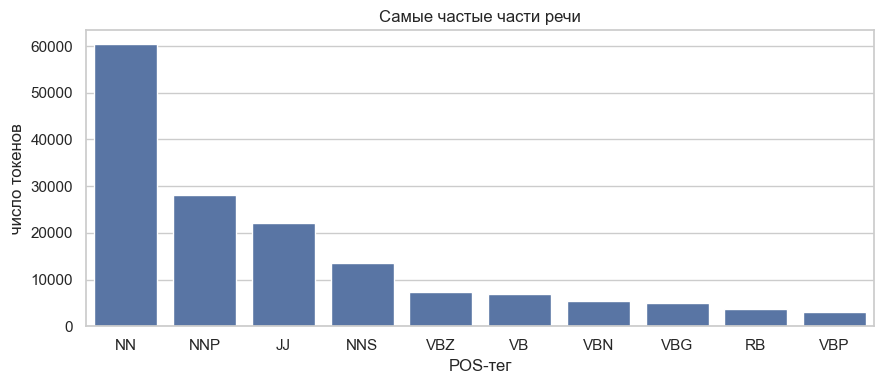

Пример частеричной разметки:
 century_NN paraplegic_JJ marine_NN dispatch_VBN moon_NN pandora_NN unique_JJ mission_NN torn_JJ follow_VBG order_NNS protect_VBG alien_JJ civilization_NN actor_sam_worthington_NNP actor_zoe_saldana_NNP actor_sigourney_weaver_NNP actor_stephen_lang_NNP actor_michelle_rodriguez_NNP director_james_cameron_NNP


,Accuracy,F1,Precision,Recall,ROC-AUC
модель,,,,,
kNN,0.560,0.605,0.633,0.579,0.600
SVM,0.619,0.685,0.660,0.711,0.624
Logistic Regression,0.621,0.686,0.662,0.711,0.640


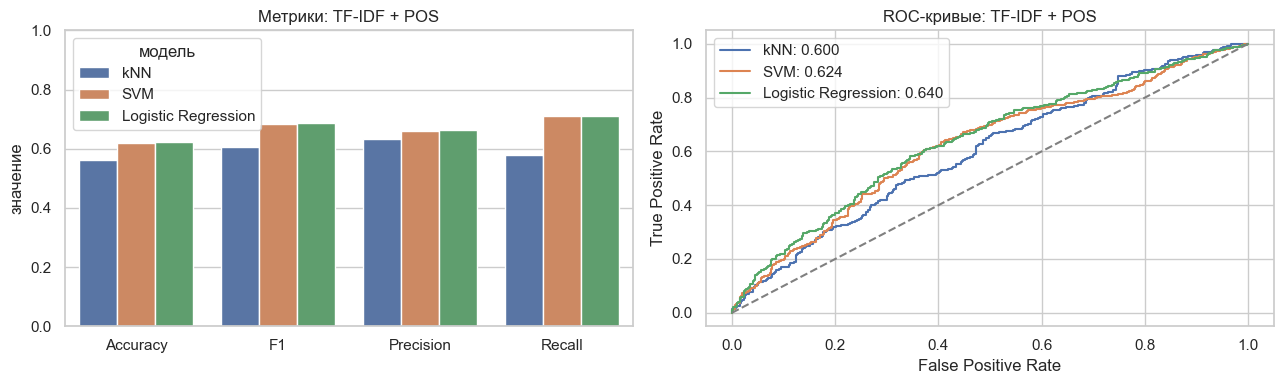

In [9]:
def pos_mark_tokens(row):
    wn_pos = {"J": "a", "V": "v", "N": "n", "R": "r"}
    tagged = [
        f"{lemmatizer.lemmatize(word, pos=wn_pos.get(tag[0], 'n'))}_{tag}"
        for word, tag in row["tagged_overview"]
        if word not in STOP_WORDS and len(word) > 1
    ]
    return tagged + [f"{token}_NNP" for token in row["metadata_tokens"]]

data["pos_tokens"] = data.apply(pos_mark_tokens, axis=1)
data["pos_text"] = data["pos_tokens"].str.join(" ")

tfidf_pos = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20_000, sublinear_tf=True)
X_train_pos = tfidf_pos.fit_transform(data.iloc[train_idx]["pos_text"])
X_test_pos = tfidf_pos.transform(data.iloc[test_idx]["pos_text"])

tag_counts = Counter(token.rsplit("_", 1)[-1] for tokens in data["pos_tokens"] for token in tokens)
top_tags = pd.Series(tag_counts).nlargest(10)
plt.figure(figsize=(9, 4))
sns.barplot(x=top_tags.index, y=top_tags.values, color="#4C72B0")
plt.title("Самые частые части речи")
plt.xlabel("POS-тег")
plt.ylabel("число токенов")
plt.tight_layout()
plt.show()

print("Пример частеричной разметки:\n", data.iloc[0]["pos_text"][:700])
results_pos = evaluate_models(X_train_pos, X_test_pos, "TF-IDF + POS")

**Интерпретация частеричной разметки.** На графике частот преобладают существительные (`NN`), собственные имена (`NNP`) и прилагательные (`JJ`). Это соответствует описаниям героев, событий и свойств. Высокая частота `NNP` дополнительно обусловлена тем, что имена актёров и режиссёров специально помечены этим тегом. Глагольные теги `VBG`, `VB`, `VBZ` и другие отражают действия и формы глаголов. Это распределение предсказанных тегов, а не проверенная вручную грамматическая разметка.

У Logistic Regression по сравнению с обычным TF-IDF F1 изменяется с 0.681 до 0.686, Accuracy — с 0.621 до 0.621, Precision — с 0.667 до 0.662, Recall — с 0.695 до 0.711. На диаграмме и ROC-графике видно, что добавление грамматических тегов даёт лишь небольшой эффект; ROC-AUC Logistic Regression составляет 0.640. Близкие результаты одного разбиения не доказывают, что POS-разметка обязательно полезна на других данных.

## 3.3. Итоговое сравнение

Сравниваются все представления одного и того же текста `overview + 5 актёров + режиссёр`. Разбиение train/test и модели во всех экспериментах одинаковы.

F1, Precision и Recall относятся к классу `1`. Для оценки разделимости дополнительно рассматривается ROC-AUC; значение 0.5 соответствует отсутствию разделения классов. Результаты на одном разбиении имеют случайную вариативность, поэтому небольшие различия не означают доказанного преимущества метода.

,представление,модель,Accuracy,F1,Precision,Recall,ROC-AUC
14,TF-IDF + POS,Logistic Regression,0.621,0.686,0.662,0.711,0.640
13,TF-IDF + POS,SVM,0.619,0.685,0.660,0.711,0.624
8,TF-IDF,Logistic Regression,0.621,0.681,0.667,0.695,0.640
7,TF-IDF,SVM,0.610,0.674,0.655,0.695,0.626
5,BoW + лемматизация,Logistic Regression,0.608,0.671,0.654,0.690,0.607
2,BoW + стемминг,Logistic Regression,0.605,0.671,0.651,0.691,0.612
4,BoW + лемматизация,SVM,0.599,0.663,0.648,0.679,0.600
1,BoW + стемминг,SVM,0.593,0.661,0.641,0.682,0.609
9,Word2Vec,kNN,0.578,0.639,0.636,0.642,0.595
12,TF-IDF + POS,kNN,0.560,0.605,0.633,0.579,0.600


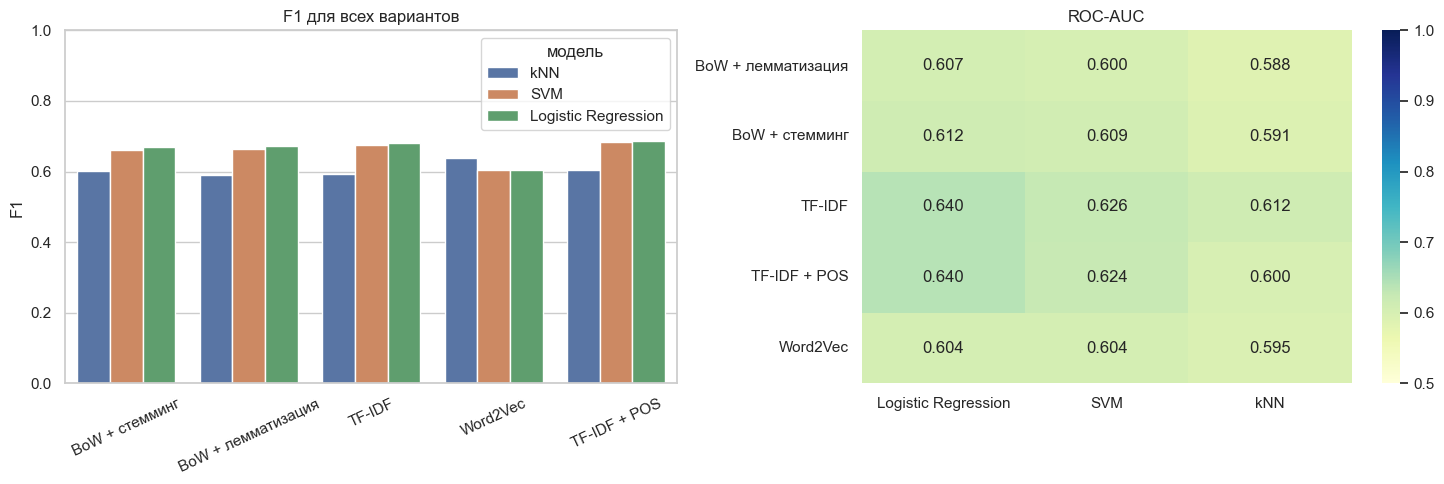

Лучшая комбинация по F1: TF-IDF + POS + Logistic Regression; Accuracy=0.621, F1=0.686, Precision=0.662, Recall=0.711, ROC-AUC=0.640.


In [10]:
all_results = pd.concat(
    [results_bow, results_lemma, results_tfidf, results_w2v, results_pos],
    ignore_index=True,
)

display(all_results.sort_values("F1", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=all_results, x="представление", y="F1", hue="модель", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_title("F1 для всех вариантов")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

auc_table = all_results.pivot(index="представление", columns="модель", values="ROC-AUC")
sns.heatmap(auc_table, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.5, vmax=1, ax=axes[1])
axes[1].set_title("ROC-AUC")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

best = all_results.loc[all_results["F1"].idxmax()]
print(
    f"Лучшая комбинация по F1: {best['представление']} + {best['модель']}; "
    f"Accuracy={best['Accuracy']:.3f}, F1={best['F1']:.3f}, "
    f"Precision={best['Precision']:.3f}, Recall={best['Recall']:.3f}, "
    f"ROC-AUC={best['ROC-AUC']:.3f}."
)

## Вывод

В работе выполнена бинарная классификация по одному составу входных данных: описание фильма, пять главных актёров и режиссёр. Реализованы базовая обработка со стеммингом, Bag of Words, повторная классификация после лемматизации, TF-IDF, Word2Vec и представление с частеричными тегами. Для всех вариантов обучены kNN, SVM и Logistic Regression на одинаковом разбиении 80/20. Векторизаторы и Word2Vec обучаются только на train; upsampling также выполняется только для train.

На итоговой столбчатой диаграмме лучшие F1 среди обученных моделей дают линейные модели с TF-IDF. Сводная тепловая карта показывает, что их ROC-AUC выше, чем у Word2Vec; кNN уступает линейным моделям в большинстве вариантов. Лемматизация сама по себе не обеспечила устойчивого выигрыша, а добавление POS-тегов изменило показатели незначительно. Следовательно, более сложная обработка текста не всегда улучшает решение.

Лучший F1 среди обученных комбинаций получен у **TF-IDF + POS и Logistic Regression**: Accuracy = 0.621, F1 = 0.686, Precision = 0.662, Recall = 0.711, ROC-AUC = 0.640. Обычный TF-IDF с Logistic Regression даёт близкий F1 = 0.681 при Accuracy = 0.621. Практически эти варианты близки по качеству; для более простого решения разумен обычный TF-IDF. Рейтинг нельзя надёжно восстановить по описанию сюжета и участникам: итоговый ROC-AUC около 0.64 указывает на ограниченную разделимость классов.

**Почему нельзя ориентироваться только на F1.** Контрольная модель, всегда предсказывающая «хороший фильм», имеет Accuracy = 0.581, F1 = 0.735 и ROC-AUC = 0.500. Её F1 выше, чем у всех обученных моделей, поскольку положительный класс преобладает и Recall такого ответа равен 1. При этом она вообще не распознаёт класс `0`. Обученные линейные модели с TF-IDF дают более высокие Accuracy и ROC-AUC, но не превосходят постоянный ответ по F1 положительного класса. Поэтому называть достигнутое качество высоким или делать вывод только по F1 было бы неправильно. Сравнение выполнено на одном тестовом разбиении; оно описывает результаты этих экспериментов и не доказывает универсального превосходства одного метода.